In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
XAUUSD_df = pd.read_csv('COMEX_GC_data.csv')
XAUUSDT_df = pd.read_csv('binance_xauusdt_1m.csv')

# Convert timestamp to datetime
XAUUSD_df["timestamp"] = pd.to_datetime(XAUUSD_df["Datetime"])
XAUUSDT_df["timestamp"] = pd.to_datetime(XAUUSDT_df["open_time"])

# Select time interval
start = "2026-11-06 12:21"
end = "2026-11-11 12:20"

XAUUSD_filtered = XAUUSD_df[
    (XAUUSD_df["timestamp"] >= start) &
    (XAUUSD_df["timestamp"] <= end)
]

XAUUSDT_filtered = XAUUSDT_df[
    (XAUUSDT_df["timestamp"] >= start) &
    (XAUUSDT_df["timestamp"] <= end)
]

print(XAUUSD_filtered.head())
print(XAUUSDT_filtered.head())

                    Datetime        Close         High          Low  \
0  2026-11-06 12:21:00+00:00  4079.100098  4079.699951  4078.000000   
1  2026-11-06 12:22:00+00:00  4079.699951  4080.199951  4078.399902   
2  2026-11-06 12:23:00+00:00  4081.600098  4082.399902  4079.500000   
3  2026-11-06 12:24:00+00:00  4079.300049  4081.899902  4079.300049   
4  2026-11-06 12:25:00+00:00  4079.600098  4080.399902  4078.600098   

          Open  Volume                 timestamp  
0  4078.000000       0 2026-11-06 12:21:00+00:00  
1  4079.199951     117 2026-11-06 12:22:00+00:00  
2  4079.500000      93 2026-11-06 12:23:00+00:00  
3  4081.699951     104 2026-11-06 12:24:00+00:00  
4  4079.399902      69 2026-11-06 12:25:00+00:00  
                       open_time     open     high      low    close   volume  \
42799  2026-11-06 12:21:00+00:00  4076.54  4078.17  4076.46  4077.74  235.878   
42800  2026-11-06 12:22:00+00:00  4077.75  4078.80  4077.35  4078.44  208.900   
42801  2026-11-06 12:23:

In [4]:
# change the timestamp to datetime and floor to the nearest minute, 
# eliminating millisecond differences
XAUUSD_filtered["timestamp"] = pd.to_datetime(XAUUSD_filtered["timestamp"]).dt.floor("min")
XAUUSDT_filtered["timestamp"] = pd.to_datetime(XAUUSDT_filtered["timestamp"]).dt.floor("min")

# merge on timestamp, keeping only rows where both datasets have values
spread_df = pd.merge(
    XAUUSD_filtered[["timestamp", "Close"]],
    XAUUSDT_filtered[["timestamp", "close"]],
    on="timestamp",
    how="inner"
)

# calculate the spread
spread_df["spread"] = spread_df["Close"] - spread_df["close"]

print(spread_df.head())

                  timestamp        Close    close    spread
0 2026-11-06 12:21:00+00:00  4079.100098  4077.74  1.360098
1 2026-11-06 12:22:00+00:00  4079.699951  4078.44  1.259951
2 2026-11-06 12:23:00+00:00  4081.600098  4080.39  1.210098
3 2026-11-06 12:24:00+00:00  4079.300049  4078.29  1.010049
4 2026-11-06 12:25:00+00:00  4079.600098  4078.29  1.310098


In [15]:
window = 120

spread_df["rolling_mean"] = (
    spread_df["spread"]
    .rolling(window=window)
    .mean()
)

window = 120

spread_df["rolling_std"] = (
    spread_df["spread"]
    .rolling(window=window)
    .std()
)

# Calculate Z-score
spread_df["z_score"] = (
    (spread_df["spread"] - spread_df["rolling_mean"])
    / spread_df["rolling_std"].replace(0, float("nan"))
)

print(
    spread_df[["spread", "rolling_mean", "rolling_std", "z_score"]]
    .tail(10)
)

        spread  rolling_mean  rolling_std   z_score
4108  1.270000      1.287592     0.192447 -0.091412
4109  1.310098      1.287425     0.192418  0.117829
4110  1.290000      1.290009     0.190324 -0.000049
4111  1.300000      1.293092     0.187419  0.036859
4112  1.229902      1.296424     0.182611 -0.364281
4113  1.290000      1.299840     0.178546 -0.055111
4114  1.089951      1.300090     0.178228 -1.179043
4115  1.249902      1.299340     0.178249 -0.277352
4116  0.869902      1.298005     0.180863 -2.367004
4117  1.330049      1.298673     0.180831  0.173510


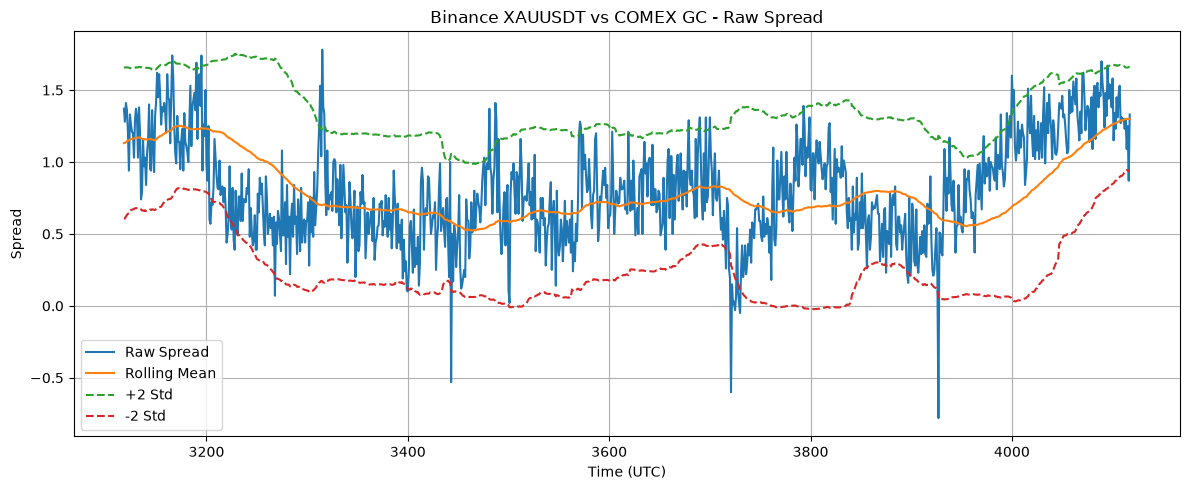

In [16]:
# Ensure datetime index
spread_df = spread_df.sort_index()

plot_df = spread_df.tail(1000)

plt.figure(figsize=(12, 5))

plt.plot(
    plot_df.index,
    plot_df["spread"],
    label="Raw Spread"
)

plt.plot(
    plot_df.index,
    plot_df["rolling_mean"],
    label="Rolling Mean"
)

plt.plot(
    plot_df.index,
    plot_df["rolling_mean"] + 2 * plot_df["rolling_std"],
    linestyle="--",
    label="+2 Std"
)

plt.plot(
    plot_df.index,
    plot_df["rolling_mean"] - 2 * plot_df["rolling_std"],
    linestyle="--",
    label="-2 Std"
)

plt.title("Binance XAUUSDT vs COMEX GC - Raw Spread")
plt.xlabel("Time (UTC)")
plt.ylabel("Spread")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [18]:
# 1. Basic descriptive statistics
print("Descriptive Statistics:")
print(spread_df["spread"].describe())

print("Variance:", spread_df["spread"].var())
print("Skewness:", spread_df["spread"].skew())
print("Kurtosis:", spread_df["spread"].kurt())

# 2. Rolling statistics
window = 120

spread_df["rolling_mean"] = (
    spread_df["spread"].rolling(window).mean().shift(1)
)

spread_df["rolling_std"] = (
    spread_df["spread"].rolling(window).std().shift(1)
)

# 3. Z-score
spread_df["z_score"] = (
    (spread_df["spread"] - spread_df["rolling_mean"])
    / spread_df["rolling_std"].replace(0, np.nan)
)

# 4. Autocorrelation
for lag in [1, 5, 10, 30, 60, 120]:
    print(
        f"Lag {lag}: "
        f"{spread_df['spread'].autocorr(lag=lag):.4f}"
    )

# 5. Inspect results
print(
    spread_df[["spread", "rolling_mean", "rolling_std", "z_score"]]
    .tail(10)
)

Descriptive Statistics:
count    4118.000000
mean        1.414824
std         0.700629
min        -4.620098
25%         0.870061
50%         1.350000
75%         1.930195
max         3.880098
Name: spread, dtype: float64
Variance: 0.49088106403060533
Skewness: 0.12743444073742644
Kurtosis: 0.6226612974192146
Lag 1: 0.9085
Lag 5: 0.8805
Lag 10: 0.8657
Lag 30: 0.8034
Lag 60: 0.7169
Lag 120: 0.6051
        spread  rolling_mean  rolling_std   z_score
4108  1.270000      1.284924     0.194895 -0.076576
4109  1.310098      1.287592     0.192447  0.116946
4110  1.290000      1.287425     0.192418  0.013381
4111  1.300000      1.290009     0.190324  0.052493
4112  1.229902      1.293092     0.187419 -0.337156
4113  1.290000      1.296424     0.182611 -0.035179
4114  1.089951      1.299840     0.178546 -1.175543
4115  1.249902      1.300090     0.178228 -0.281591
4116  0.869902      1.299340     0.178249 -2.409206
4117  1.330049      1.298005     0.180863  0.177173


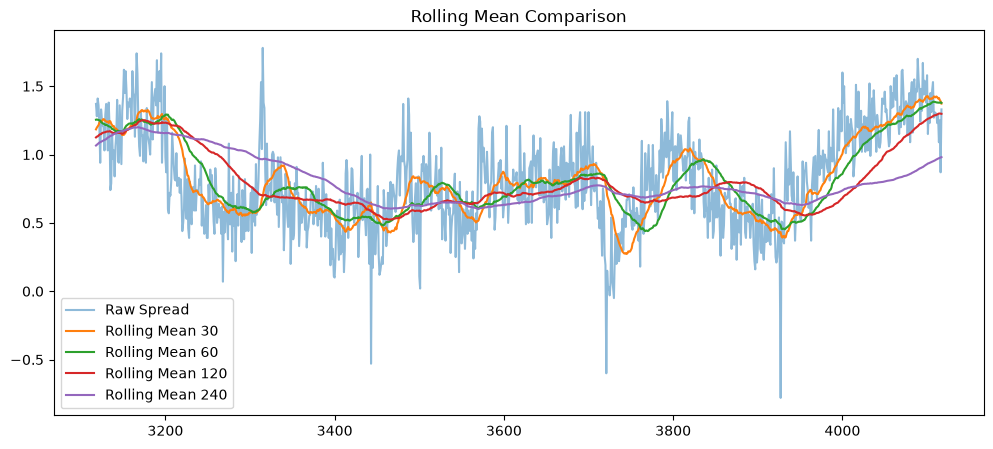

In [19]:
windows = [30, 60, 120, 240]

for w in windows:
    spread_df[f"mean_{w}"] = (
        spread_df["spread"]
        .rolling(w)
        .mean()
        .shift(1)
    )

    spread_df[f"std_{w}"] = (
        spread_df["spread"]
        .rolling(w)
        .std()
        .shift(1)
    )

    spread_df[f"z_{w}"] = (
        (spread_df["spread"] - spread_df[f"mean_{w}"])
        / spread_df[f"std_{w}"]
    )

    import matplotlib.pyplot as plt

plot_df = spread_df.tail(1000)

plt.figure(figsize=(12, 5))

plt.plot(
    plot_df.index,
    plot_df["spread"],
    label="Raw Spread",
    alpha=0.5
)

for w in windows:
    plt.plot(
        plot_df.index,
        plot_df[f"mean_{w}"],
        label=f"Rolling Mean {w}"
    )

plt.legend()
plt.title("Rolling Mean Comparison")
plt.show()